# Segundo Examen Parcial - Control Difuso y Algoritmos Geneticos

 *Optimización Multiobjetivo de Sistemas Difusos mediante Algoritmos Geneticos con **PyGAD*** 

### **Objetivo**

Utilizar la biblioteca pyGAD para optimizar automáticamente sistemas de inferencia difusa tipo Mamdani empleados para el control de un servomotor de corriente directa.


#### Importaciones

In [42]:
import multiprocessing
import threading
import time
import timeit
import tracemalloc

import matplotlib.pyplot as plt
import numpy as np
import psutil
import pygad
import skfuzzy as fuzz
from scipy.signal import lsim, lti, square
from skfuzzy import control as ctrl

#### Constantes obligatorias

In [43]:
# Universos de discurso
ERROR_MIN, ERROR_MAX = -np.pi/2, np.pi/2
DERROR_MIN, DERROR_MAX = -np.pi/6, np.pi/6
VOLTAGE_MIN, VOLTAGE_MAX = -8.18, 8.18
N_PUNTOS_UNIVERSO = 1000

# Simulación obligatoria
T_SIM = 200       # segundos
PERIODO = 100     # segundos, referencia cuadrada ±1 rad, ciclo útil 50 %

DT_REFERENCIA = 0.1
TOL_INICIO = 0.1     # rad, cada transición debe partir a menos de 0.1 rad de la referencia anterior

TR0 = 9      # segundos
TS0 = 13     # segundos

# Codificación genética
ANCHURA_MIN, ANCHURA_MAX = 0.25, 1.5     # anchura w, en múltiplos de la separación entre términos de automf
SOLAPE_MIN, SOLAPE_MAX = 1.0, 2.5        # solapamiento o

# Algoritmo genético
SOL_PER_POP = 26
NUM_GENERATIONS = 30
NUM_PARENTS_MATING = 12
KEEP_ELITISM = 2
MUTATION_PERCENT_GENES = 10
SEMBRAR_BASELINE = True                  # población inicial: 1 base automf + 40 % perturbados + el resto aleatorios
FRAC_PERTURBADOS = 0.4
PROCESOS = 12                            # procesos en paralelo de pyGAD (None = en serie)

# Protocolo
TERMINOS = (5, 7, 9)
SEMILLAS = [1, 2, 3, 4, 5]
ARCHIVO_RESULTADOS = 'resultados_ag_v2.npy'  # permite reanudar una corrida larga interrumpida
REUSAR_RESULTADOS = True

### **Fase 1:** Implementación de los controladores base

- Controlador A. Sistema difuso con: **5 términos lingüísticos por entrada** (generados con automf)
- Controlador B. Sistema difuso con: **7 términos lingüísticos por entrada** (generados con automf)
- Controlador C. Sistema difuso con: **9 términos lingüísticos por entrada** (generados con automf) 

#### Planta, tiempo y referencia

In [44]:
G = lti([0.5], [1, 13.6667, 23.3487, 0])

dt = DT_REFERENCIA
t = np.arange(0, T_SIM + dt, dt)

r = square(2*np.pi*t/PERIODO)

x0 = [0, 0, 0]

* Cada variable tiene N términos generados con `automf` y la base usa todas las reglas (N² reglas). `automf` solo trae nombres para 3, 5 y 7 términos, por eso se pasan los nombres explícitos.
* Consecuente de cada regla: el término del error `y`, cuando el error es `ZE`, el término del cambio.
* Cuando la referencia cambia, `e` vale ±2 rad y `de` ≈ ±20 rad/s, fuera de los universos. `skfuzzy` satura las entradas en el borde del universo (`clip_to_bounds=True`, valor por defecto); sin eso `compute()` lanza `IndexError`.

In [45]:
def crear_controlador(nombres):
    n = len(nombres)
    error = ctrl.Antecedent(np.linspace(ERROR_MIN, ERROR_MAX, 1000), 'error')
    derror = ctrl.Antecedent(np.linspace(DERROR_MIN, DERROR_MAX, 1000), 'derror')
    voltage = ctrl.Consequent(np.linspace(VOLTAGE_MIN, VOLTAGE_MAX, 1000), 'voltage')
    for variable in (error, derror, voltage):
        variable.automf(n, names=nombres)

    reglas = []
    for i in range(n):
        for j in range(n):
            k = i if i != n // 2 else j
            reglas.append(ctrl.Rule(error[nombres[i]] & derror[nombres[j]], voltage[nombres[k]]))
    return ctrl.ControlSystemSimulation(ctrl.ControlSystem(reglas))

NOMBRES = {5: ['NB', 'NS', 'ZE', 'PS', 'PB'],
           7: ['NB', 'NM', 'NS', 'ZE', 'PS', 'PM', 'PB'],
           9: ['NVB', 'NB', 'NM', 'NS', 'ZE', 'PS', 'PM', 'PB', 'PVB']}

controller_A = crear_controlador(NOMBRES[5])
controller_B = crear_controlador(NOMBRES[7])
controller_C = crear_controlador(NOMBRES[9])

#### Funciones de membresia generadas por `automf`

##### Controlador A

/home/Jesus/miniconda3/envs/ml-course/lib/python3.11/site-packages/skfuzzy/control/fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


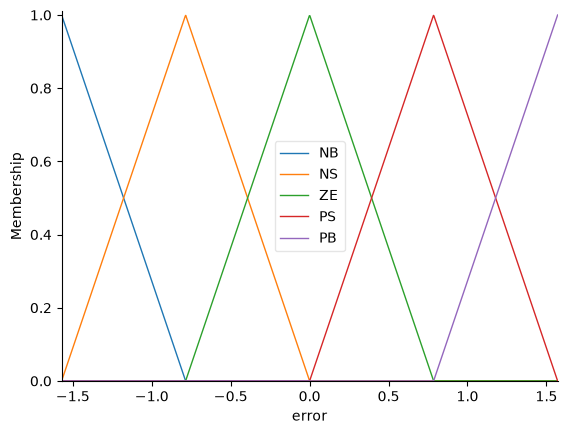

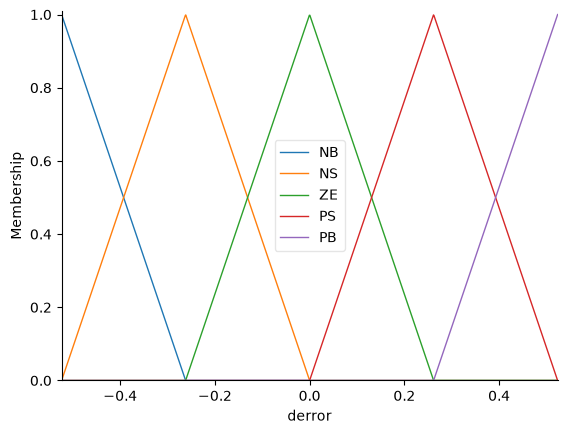

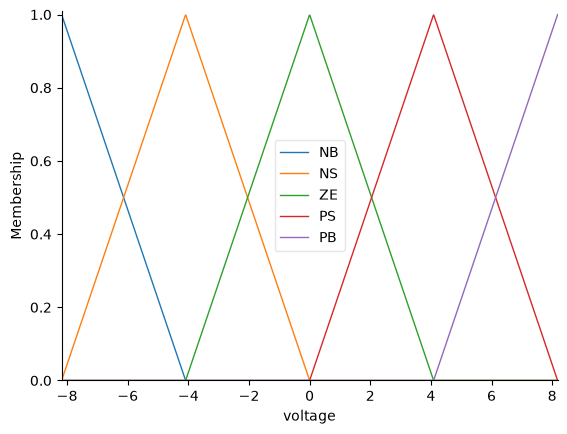

In [46]:
for variable in list(controller_A.ctrl.antecedents) + list(controller_A.ctrl.consequents):
    variable.view()

#### Simulación del lazo cerrado
En lazo cerrado el voltaje *$u$* depende de *$theta$*, así que no se puede llamar a `lsim` una sola vez con todo *$u$*.
Se llama a `lsim` en cada intervalo con el voltaje *$u_k$* constante y *$x_0$* igual al estado final del intervalo anterior. `lsim` toma *$x_0$* como el estado en $t = 0$, por eso cada intervalo se simula con `T = t[:2] = [0, dt]` y no con el tiempo absoluto del intervalo.

Con `dt = 0.1 s` cada simulación de 200 s hace 2 000 inferencias difusas; simular los tres controladores tarda unos 2 minutos.

In [47]:
def paso_planta(u, t, x0):
    tout, theta, xout = lsim(G, U=u, T=t, X0=x0)
    return theta[-1], xout[-1]

def simular(controller):
    theta = np.zeros(len(t))
    u = np.zeros(len(t))
    tiempos = []
    x = x0
    for k in range(len(t) - 1):
        i = max(k - 1, 0)
        e = r[i:k+1] - theta[i:k+1]
        de = np.diff(e, prepend=e[0]) / dt
        controller.input['error'] = e[-1]
        controller.input['derror'] = de[-1]
        start = time.perf_counter()
        controller.compute()
        end = time.perf_counter()
        inference_time = end - start
        tiempos.append(inference_time)
        u[k] = controller.output['voltage']
        theta[k+1], x = paso_planta([u[k], u[k]], t[:2], x)
    return theta, u, np.mean(tiempos)

#### Métricas de desempeño y fitness

Solo se evalúan la transición positiva ($−1 \rightarrow +1$, de 100 a 150 s) y la negativa ($+1 \rightarrow -1$, de 50 a 100 s); el resto de la simulación se descarta.

- **OS (%)**: lo que la respuesta sobresale de la referencia, en % de $|r| = 1 rad$. En la Ec. 12 entra como fracción (2 % = 0.02).
- **$t_r$ (s)**: tiempo entre el 10 % y el 90 % del salto de la referencia: la respuesta debe pasar de $-0.8\,r$ a $+0.8\,r$ (salto de 2 rad). Si nunca llega al 90 % del salto, $t_r$ no está definido y su término vale 0 (equivale a la "U" de la Tabla 13 del artículo).
- **$t_s$ (s)**: tiempo desde el cambio de referencia hasta que $|e|$ queda por debajo del 5 % de la referencia (0.05 rad) sin volver a salir de esa banda.
- **SSE (rad)**: promedio del error, con signo, desde $t_s$ hasta el siguiente cambio de referencia.
- **q** (Ec. 13): la fórmula del enunciado, global sobre los 200 s y la misma en ambas transiciones.
- **Pesos**: iguales, w = 1/8. Las ocho métricas tienen la misma importancia, como en el artículo.

**Decisiones propias**, porque el enunciado y el artículo no las precisan:

- Banda de $t_s$: 5 % de $|r|$ = 0.05 rad. Si no hay $t_s$, el SSE se promedia en los últimos 5 s de la ventana y el término de $t_s$ vale 0.
- Cada término de tiempo se limita a 1, porque el artículo dice que $f_1 \ldots f_4 \in [0, 1]$.
- **Niveles fijos para $t_r$.** La Figura 5 del artículo mide el $t_r$ "falso" sobre la excursión propia de la respuesta y lo corrige con $\rho$ (Ec. 13). En una primera corrida completa (15 corridas, $t_r$ sobre la excursión propia y $\rho$ literal) 7 controladores resultaron degenerados (nunca llegan a la referencia negativa o ya parten lejos de la referencia anterior) y aun así recibieron fitness de hasta 0.85, porque $\rho$ global vale ≈ 1 y no los penaliza. Por eso $t_r$ se mide con niveles fijos (±0.8 rad) y, además, se aplica una penalización directa de inicio (ver Fase 2).

In [48]:
w = [1/8] * 8

def medir_transicion(theta, t_cambio, t_siguiente):
    i0, i1 = round(t_cambio / dt), round(t_siguiente / dt)
    th = theta[i0:i1]                    # respuesta entre dos cambios de referencia
    tv = t[i0:i1] - t[i0]                # tiempo medido desde el cambio de referencia
    ref = r[i0]                          # nuevo nivel de la referencia (+1 o -1)
    e = ref - th

    # Sobreimpulso (%): lo que sobresale respecto de la referencia
    OS = 100 * max(0, np.max(ref * (th - ref)))

    # Tiempo de crecimiento: del 10 % al 90 % del salto de la referencia (de -ref a +ref, 2 rad)
    avance = (th + ref) / (2 * ref)      # 0 en la referencia anterior, 1 en la nueva
    if avance.max() < 0.9:
        tr = np.inf                      # nunca llega al 90 % del salto: t_r no está definido
    else:
        tr = tv[np.argmax(avance >= 0.9)] - tv[np.argmax(avance >= 0.1)]

    # Tiempo de establecimiento: después de la última muestra con |e| >= 0.05 rad
    fuera = np.nonzero(np.abs(e) >= 0.05)[0]
    if len(fuera) == 0 or fuera[-1] == len(e) - 1:
        ts = np.inf
        k = len(e) - round(5 / dt)       # sin t_s: se promedian los últimos 5 s
    else:
        k = fuera[-1] + 1
        ts = tv[k]

    # Error en estado estable: promedio del error (con signo) después de t_s
    SSE = np.mean(e[k:])
    return OS, SSE, tr, ts

def factor_q(theta):
    return (r.max() - theta.min()) / (theta.max() - theta.min())      # Ec. 13

def evaluar(theta):
    OS_pos, SSE_pos, tr_pos, ts_pos = medir_transicion(theta, 100, 150)    # transición positiva
    OS_neg, SSE_neg, tr_neg, ts_neg = medir_transicion(theta, 50, 100)     # transición negativa
    q = factor_q(theta)
    # OS se mide en %; en la Ec. 12 entra como fracción (2 % = 0.02).
    # Los términos de tiempo se limitan a 1 (el artículo dice que f1..f4 están en [0, 1]).
    fitness = (w[0] / (1 + abs(OS_pos / 100)) + w[1] / (1 + abs(SSE_pos)) + w[2] * min(1, TR0 / (q * tr_pos)) + w[3] * min(1, TS0 / ts_pos)
                + w[4] / (1 + abs(OS_neg / 100)) + w[5] / (1 + abs(SSE_neg)) + w[6] * min(1, TR0 / (q * tr_neg)) + w[7] * min(1, TS0 / ts_neg))
    return {'OS+': OS_pos, 'OS-': OS_neg, 'SSE+': SSE_pos, 'SSE-': SSE_neg,
            'tr+': tr_pos, 'tr-': tr_neg, 'ts+': ts_pos, 'ts-': ts_neg, 'q': q, 'fitness': fitness}

#### Simulación de los controladores base

In [49]:
controladores = {'A': controller_A, 'B': controller_B, 'C': controller_C}
resultados = {}
for nombre, controller in controladores.items():
    theta, u, inference_time = simular(controller)
    resultados[nombre] = {'theta': theta, 'tiempo_inferencia_ms': 1000 * inference_time,
                          'reglas': len(list(controller.ctrl.rules))}

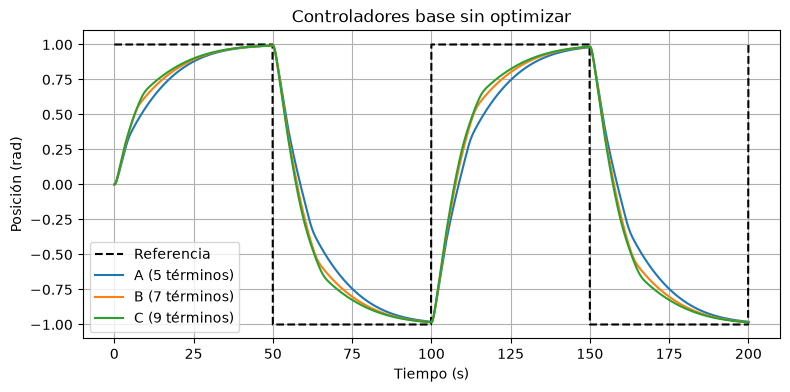

In [50]:
plt.figure(figsize=(9, 4))
plt.plot(t, r, 'k--', label='Referencia')
for nombre, etiqueta in (('A', 'A (5 términos)'), ('B', 'B (7 términos)'), ('C', 'C (9 términos)')):
    plt.plot(t, resultados[nombre]['theta'], label=etiqueta)
plt.xlabel('Tiempo (s)')
plt.ylabel('Posición (rad)')
plt.title('Controladores base sin optimizar')
plt.grid(True)
plt.legend()
plt.show()

#### Registro de métricas de los controladores base sin optimizar

In [51]:
for nombre in resultados:
    resultados[nombre].update(evaluar(resultados[nombre]['theta']))

filas = [('OS+ (%)', 'OS+'), ('OS- (%)', 'OS-'), ('SSE+ (rad)', 'SSE+'), ('SSE- (rad)', 'SSE-'),
         ('tr+ (s)', 'tr+'), ('tr- (s)', 'tr-'), ('ts+ (s)', 'ts+'), ('ts- (s)', 'ts-'), ('q', 'q'),
         ('Fitness total', 'fitness'), ('Reglas totales', 'reglas'), ('Inferencia (ms)', 'tiempo_inferencia_ms')]
print(f"{'Métrica':<18}" + ''.join(f"{'Controlador ' + nombre:>16}" for nombre in resultados))
for etiqueta, clave in filas:
    print(f"{etiqueta:<18}" + ''.join(f"{resultados[nombre][clave]:>16.4f}" for nombre in resultados))

Métrica              Controlador A   Controlador B   Controlador C
OS+ (%)                     0.0000          0.0000          0.0000
OS- (%)                     0.0000          0.0000          0.0000
SSE+ (rad)                  0.0327          0.0301          0.0295
SSE- (rad)                 -0.0328         -0.0303         -0.0296
tr+ (s)                    25.9000         23.1000         21.6000
tr- (s)                    25.9000         23.1000         21.6000
ts+ (s)                    41.6000         39.7000         38.9000
ts- (s)                    41.7000         39.7000         38.9000
q                           1.0040          1.0037          1.0036
Fitness total               0.6566          0.6716          0.6802
Reglas totales             25.0000         49.0000         81.0000
Inferencia (ms)             8.2230         18.4936         38.8202


### **Fase 2:** Optimización mediante **PyGAD**

- 26 individuos
- 30 generaciones


#### Codificación genética
Cada función de membresía (MF) de las dos entradas y de la salida lleva **4 genes**: centro `c`, anchura `w`, forma `f` y solapamiento `o`. Sus vértices trapezoidales son `[c − w·o, c − w·f, c + w·f, c + w·o]`; con `f = 0` la MF es un triángulo. Como `f ≤ 1 ≤ o`, siempre se cumple `a ≤ b ≤ c ≤ d`. Cada regla lleva **2 genes**: activación (1 = activa, 0 = inactiva) y consecuente (término de salida).

Cromosoma = 3 variables × 4 genes × N términos + N² activaciones + N² consecuentes $\rightarrow$ **110 genes (N = 5), 182 (N = 7) y 270 (N = 9)**.

**Reparación** (antes de construir el sistema): cada gen se recorta a su rango, los términos se ordenan por su centro, los vértices se recortan al universo y los términos extremos se extienden hasta el borde del universo, como hace `automf`.

**Penalización directa** (fitness = 0): ninguna regla activa, MF degeneradas (base menor que dos pasos del universo), algún instante del lazo en el que ninguna regla se activa, o una respuesta que no parte de la meseta anterior (|θ(50 s) − 1| > 0.1 rad o |θ(100 s) + 1| > 0.1 rad): sin esa condición, un controlador que no completa la transición anterior podría puntuar como si la hubiera completado.

#### Parámetros del algoritmo genético y su justificación
| Parámetro | Valor | Justificación |
|---|---|---|
| Población | 26 | El enunciado pide al menos 20. Con 12 procesos y 2 élites, 24 individuos nuevos por generación llenan justo dos rondas de 12 |
| Generaciones | 30 | Mínimo del enunciado; el costo crece linealmente con ellas |
| Selección de padres | torneo, K = 3 | Presión de selección moderada; con fitness entre 0.6 y 1 la ruleta casi no distinguiría individuos |
| Padres que se cruzan | 12 | Cerca de la mitad de la población |
| Cruce | uniforme | Los genes son de naturaleza distinta (parámetros de MF, activaciones y consecuentes) y no hay un orden que respetar |
| Mutación | aleatoria, 10 % de los genes | Con solo 30 generaciones hace falta exploración; la élite impide perder al mejor |
| Elitismo | 2 | Conserva a los dos mejores individuos |
| Población inicial | 1 base `automf` + 40 % perturbados + aleatorios | Parte de individuos válidos; pendiente de confirmar con el profesor |
| Pesos de la Ec. 12 | 1/8 | Ocho métricas con la misma importancia, como en el artículo |

Estos valores no se afinaron experimentalmente porque cada corrida tarda horas.

In [52]:
multiprocessing.set_start_method('fork', force=True)    # pyGAD crea sus procesos con 'fork' (en Python 3.14 el valor por defecto cambió)

UNIVERSOS = (('error', ERROR_MIN, ERROR_MAX), ('derror', DERROR_MIN, DERROR_MAX), ('voltage', VOLTAGE_MIN, VOLTAGE_MAX))

def num_genes(n):
    return 3 * 4 * n + 2 * n * n

def limites_genes(n):
    """Mínimo y máximo de cada gen: por variable [c, w, f, o] x n; después activaciones y consecuentes."""
    minimo, maximo = [], []
    for _, lo, hi in UNIVERSOS:
        d = (hi - lo) / (n - 1)                  # separación entre términos de automf
        minimo += [lo] * n + [ANCHURA_MIN * d] * n + [0.0] * n + [SOLAPE_MIN] * n
        maximo += [hi] * n + [ANCHURA_MAX * d] * n + [1.0] * n + [SOLAPE_MAX] * n
    minimo += [0] * (2 * n * n)
    maximo += [1] * (n * n) + [n - 1] * (n * n)
    return np.array(minimo, dtype=float), np.array(maximo, dtype=float)

def crear_gene_space(n):
    minimo, maximo = limites_genes(n)
    espacio = [{'low': float(minimo[k]), 'high': float(maximo[k])} for k in range(12 * n)]
    espacio += [list(range(int(maximo[k]) + 1)) for k in range(12 * n, len(minimo))]
    return espacio

def decodificar(genes, n):
    """Repara el cromosoma y devuelve (mfs, activas, consecuentes, degeneradas); mfs = 3 arreglos (n, 4) con [a, b, c, d]."""
    minimo, maximo = limites_genes(n)
    genes = np.clip(np.asarray(genes, dtype=float), minimo, maximo)        # cada gen dentro de su rango
    mfs, degeneradas = [], 0
    for v, (_, lo, hi) in enumerate(UNIVERSOS):
        centro, ancho, forma, solape = genes[4 * n * v: 4 * n * (v + 1)].reshape(4, n)
        orden = np.argsort(centro, kind='stable')                          # términos ordenados por su centro
        centro, ancho, forma, solape = centro[orden], ancho[orden], forma[orden], solape[orden]
        vertices = np.column_stack([centro - ancho * solape, centro - ancho * forma,
                                    centro + ancho * forma, centro + ancho * solape])
        vertices = np.clip(vertices, lo, hi)                               # dentro del universo
        vertices[0, :2] = lo                                               # los términos extremos llegan al borde
        vertices[-1, 2:] = hi
        degeneradas += int(np.sum(vertices[:, 3] - vertices[:, 0] < 2 * (hi - lo) / 999))
        mfs.append(vertices)
    activas = np.round(genes[12 * n: 12 * n + n * n]).astype(int).reshape(n, n)
    consecuentes = np.round(genes[12 * n + n * n:]).astype(int).reshape(n, n)
    return mfs, activas, consecuentes, degeneradas

def individuo_baseline(n):
    """Cromosoma que reproduce el controlador de automf de la Fase 1 (todas las reglas, misma tabla)."""
    genes = []
    for _, lo, hi in UNIVERSOS:
        d = (hi - lo) / (n - 1)
        genes += list(np.linspace(lo, hi, n)) + [d] * n + [0.0] * n + [SOLAPE_MIN] * n
    genes += [1] * (n * n)
    genes += [i if i != n // 2 else j for i in range(n) for j in range(n)]
    return np.array(genes, dtype=float)

def poblacion_inicial(n, rng):
    minimo, maximo = limites_genes(n)
    k = 12 * n                                                             # los primeros k genes son continuos

    def aleatorio():
        genes = np.empty(len(minimo))
        genes[:k] = rng.uniform(minimo[:k], maximo[:k])
        genes[k:] = rng.integers(minimo[k:].astype(int), maximo[k:].astype(int) + 1)
        return genes

    poblacion = []
    if SEMBRAR_BASELINE:
        base = individuo_baseline(n)
        poblacion.append(base)
        for _ in range(int(FRAC_PERTURBADOS * SOL_PER_POP)):
            genes = base.copy()
            ruido = rng.normal(0, 0.1 * (maximo - minimo)[:k])
            genes[:k] = np.clip(genes[:k] + ruido, minimo[:k], maximo[:k])
            activas, consecuentes = genes[k:k + n * n], genes[k + n * n:]  # vistas de genes
            cambia = rng.random(n * n) < 0.05                              # 5 % de las reglas se alteran
            activas[cambia] = 1 - activas[cambia]
            cambia = rng.random(n * n) < 0.05
            consecuentes[cambia] = rng.integers(0, n, size=int(cambia.sum()))
            poblacion.append(genes)
    while len(poblacion) < SOL_PER_POP:
        poblacion.append(aleatorio())
    return np.array(poblacion[:SOL_PER_POP], dtype=float)


### Construcción del sistema difuso y evaluación de un individuo
La evaluación es la misma de la Fase 1: simulación completa de 200 s, las ocho métricas y las Ecs. 12 y 13.

In [53]:
def construir_sistema_difuso(mfs, activas, consecuentes, n):
    nombres = NOMBRES[n]
    error = ctrl.Antecedent(np.linspace(ERROR_MIN, ERROR_MAX, 1000), 'error')
    derror = ctrl.Antecedent(np.linspace(DERROR_MIN, DERROR_MAX, 1000), 'derror')
    voltage = ctrl.Consequent(np.linspace(VOLTAGE_MIN, VOLTAGE_MAX, 1000), 'voltage')
    for variable, vertices in zip((error, derror, voltage), mfs):
        for nombre, vertice in zip(nombres, vertices):
            variable[nombre] = fuzz.trapmf(variable.universe, vertice)
    reglas = [ctrl.Rule(error[nombres[i]] & derror[nombres[j]], voltage[nombres[consecuentes[i, j]]])
              for i in range(n) for j in range(n) if activas[i, j]]
    return ctrl.ControlSystemSimulation(ctrl.ControlSystem(reglas))

def evaluar_individuo(genes, n):
    mfs, activas, consecuentes, degeneradas = decodificar(genes, n)
    if activas.sum() == 0 or degeneradas > 0:
        return {'fitness': 0.0}                                            # penalización directa
    controller = construir_sistema_difuso(mfs, activas, consecuentes, n)
    try:
        theta, u, inference_time = simular(controller)
    except (KeyError, ValueError):                                         # en algún instante ninguna regla se activó
        return {'fitness': 0.0}                                            # penalización directa
    if abs(theta[round(50 / dt)] - 1) > TOL_INICIO or abs(theta[round(100 / dt)] + 1) > TOL_INICIO:
        return {'fitness': 0.0}                                            # no parte de la meseta anterior
    evaluacion = evaluar(theta)
    evaluacion.update(theta=theta, inferencia_ms=1000 * inference_time, reglas_activas=int(activas.sum()))
    return evaluacion

def listar_reglas(genes, n):
    _, activas, consecuentes, _ = decodificar(genes, n)
    nombres = NOMBRES[n]
    return [f'SI error es {nombres[i]} Y derror es {nombres[j]} ENTONCES voltage es {nombres[consecuentes[i, j]]}'
            for i in range(n) for j in range(n) if activas[i, j]]

N_TERMINOS = 5     # tamaño del sistema que evalúa fitness_func; lo fija ejecutar_ag

def fitness_func(ga_instance, solution, solution_idx):
    # Función de nivel de módulo (no anidada) para que pyGAD pueda repartirla entre procesos
    return evaluar_individuo(solution, N_TERMINOS)['fitness']

### Metricas de rendimiento 

In [54]:
def ram_total_mb():
    """RAM (PSS, solo Linux) del proceso principal y de sus procesos hijos, en MB."""
    proceso = psutil.Process()
    total = 0
    for p in [proceso] + proceso.children(recursive=True):
        try:
            total += p.memory_full_info().pss
        except psutil.NoSuchProcess:
            pass
    return total / 1024 ** 2

class MonitorRAM(threading.Thread):
    """Mide la RAM total cada 0.5 s mientras corre el algoritmo genético y guarda el pico."""
    def __init__(self):
        super().__init__(daemon=True)
        self.pico = 0.0
        self.activo = True

    def run(self):
        while self.activo:
            self.pico = max(self.pico, ram_total_mb())
            time.sleep(0.5)

def mostrar_progreso(ga_instance):
    print(f'   generación {ga_instance.generations_completed:>2}: mejor fitness = {ga_instance.best_solutions_fitness[-1]:.4f}')

def memoria_controlador_mb(genes, n):
    """Memoria retenida por el controlador construido y usado una vez (tracemalloc), en MB."""
    mfs, activas, consecuentes, _ = decodificar(genes, n)
    tracemalloc.start()
    controller = construir_sistema_difuso(mfs, activas, consecuentes, n)
    controller.input['error'] = 0.1
    controller.input['derror'] = 0.0
    try:
        controller.compute()
    except (KeyError, ValueError):                       # ninguna regla se activa con esta entrada de prueba
        pass
    retenida, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return retenida / 1024 ** 2


### Algoritmo Genético

In [55]:

def ejecutar_ag(n, semilla, generaciones=NUM_GENERATIONS):
    global N_TERMINOS
    N_TERMINOS = n
    rng = np.random.default_rng(semilla)
    ga_instance = pygad.GA(
        num_generations=generaciones,
        num_parents_mating=NUM_PARENTS_MATING,
        fitness_func=fitness_func,
        sol_per_pop=SOL_PER_POP,
        num_genes=num_genes(n),
        initial_population=poblacion_inicial(n, rng),
        gene_space=crear_gene_space(n),
        gene_type=[float] * (12 * n) + [int] * (2 * n * n),
        parent_selection_type='tournament',
        K_tournament=3,
        keep_elitism=KEEP_ELITISM,
        crossover_type='uniform',
        mutation_type='random',
        mutation_percent_genes=MUTATION_PERCENT_GENES,
        parallel_processing=['process', PROCESOS] if PROCESOS else None,
        on_generation=mostrar_progreso,
        random_seed=semilla,
        suppress_warnings=True,
    )

    monitor = MonitorRAM()
    monitor.start()
    start = time.time()
    ga_instance.run()
    end = time.time()
    optimization_time = end - start
    monitor.activo = False

    genes, fitness_ga, _ = ga_instance.best_solution(pop_fitness=ga_instance.last_generation_fitness)
    genes = np.array(genes, dtype=float)
    evaluacion = evaluar_individuo(genes, n)            # el mejor individuo se vuelve a evaluar en el proceso principal
    if abs(evaluacion['fitness'] - fitness_ga) > 1e-9:
        print(f'   AVISO: fitness re-evaluado {evaluacion["fitness"]:.6f} distinto del del AG {fitness_ga:.6f}')
    return {'n': n, 'semilla': semilla, 'genes': genes, 'evaluacion': evaluacion, 'fitness': evaluacion['fitness'],
            'reglas': listar_reglas(genes, n), 'n_genes': num_genes(n), 'tiempo_optimizacion': optimization_time,
            'ram_mb': monitor.pico, 'mem_controlador_mb': memoria_controlador_mb(genes, n), 'historial': list(ga_instance.best_solutions_fitness)}

### Prueba piloto

In [56]:
def piloto(generaciones=2):
    total_h = 0
    for n in TERMINOS:
        res = ejecutar_ag(n, 0, generaciones)
        horas = res['tiempo_optimizacion'] / generaciones * NUM_GENERATIONS * len(SEMILLAS) / 3600
        total_h += horas
        print(f"{n} términos: {res['tiempo_optimizacion'] / generaciones:.0f} s por generación -> ≈{horas:.1f} h para {len(SEMILLAS)} semillas")
    print(f'Tiempo total estimado: ≈{total_h:.1f} h')

# piloto()

### Ejecución final 

In [57]:
FIRMA = repr((SOL_PER_POP, NUM_GENERATIONS, NUM_PARENTS_MATING, KEEP_ELITISM, MUTATION_PERCENT_GENES, SEMBRAR_BASELINE,
              FRAC_PERTURBADOS, ANCHURA_MIN, ANCHURA_MAX, SOLAPE_MIN, SOLAPE_MAX, float(dt), tuple(w), TERMINOS, tuple(SEMILLAS), 'fitness_v2', TOL_INICIO))

resultados_ag = {}

In [58]:
if REUSAR_RESULTADOS:
    try:
        guardado = np.load(ARCHIVO_RESULTADOS, allow_pickle=True).item()
        if guardado['firma'] == FIRMA:
            resultados_ag = guardado['resultados']
            print(f'Se reanuda con {len(resultados_ag)} corridas ya guardadas')
        else:
            print('Los resultados guardados son de otra configuración y se ignoran')
    except FileNotFoundError:
        pass

for n in TERMINOS:
    for semilla in SEMILLAS:
        if (n, semilla) in resultados_ag:
            continue
        print(f'[{n} términos | semilla {semilla}] optimizando...')
        resultados_ag[(n, semilla)] = ejecutar_ag(n, semilla)
        np.save(ARCHIVO_RESULTADOS, np.array({'firma': FIRMA, 'resultados': resultados_ag}, dtype=object), allow_pickle=True)
        res = resultados_ag[(n, semilla)]
        print(f"   -> fitness = {res['fitness']:.4f}, reglas activas = {res['evaluacion'].get('reglas_activas', 0)}, "
              f"tiempo = {res['tiempo_optimizacion']:.0f} s")

[5 términos | semilla 1] optimizando...
   generación  1: mejor fitness = 0.6566
   generación  2: mejor fitness = 0.6566
   generación  3: mejor fitness = 0.6566
   generación  4: mejor fitness = 0.6566
   generación  5: mejor fitness = 0.6566
   generación  6: mejor fitness = 0.6566
   generación  7: mejor fitness = 0.6566
   generación  8: mejor fitness = 0.6566
   generación  9: mejor fitness = 0.6566
   generación 10: mejor fitness = 0.6566
   generación 11: mejor fitness = 0.6566
   generación 12: mejor fitness = 0.6566
   generación 13: mejor fitness = 0.6566
   generación 14: mejor fitness = 0.6566
   generación 15: mejor fitness = 0.6566
   generación 16: mejor fitness = 0.6566
   generación 17: mejor fitness = 0.6566
   generación 18: mejor fitness = 0.6566
   generación 19: mejor fitness = 0.6566
   generación 20: mejor fitness = 0.6566
   generación 21: mejor fitness = 0.6566
   generación 22: mejor fitness = 0.6566
   generación 23: mejor fitness = 0.6566
   generación 24:

## Curva de convergencia, respuesta temporal y mejor cromosoma

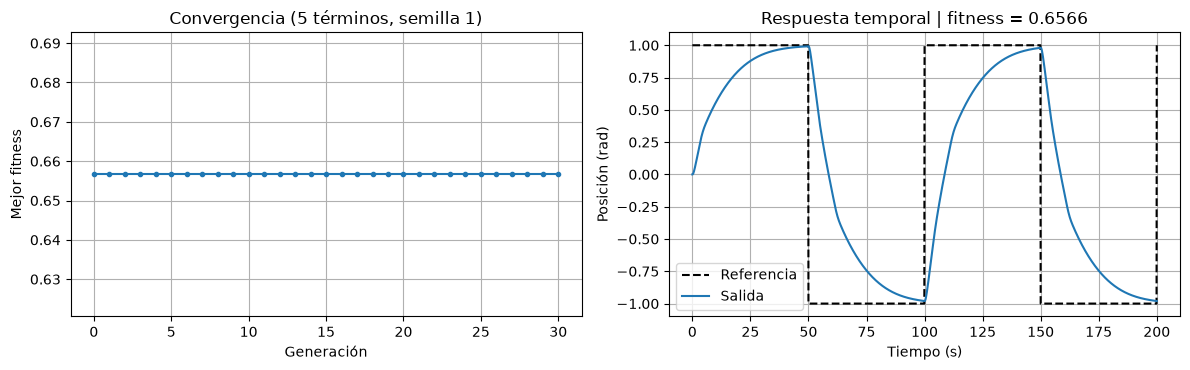

Mejor cromosoma (110 genes) [5 términos | semilla 1]:
[-1.5708 -0.7854  0.      0.7854  1.5708  0.7854  0.7854  0.7854  0.7854  0.7854  0.      0.      0.      0.      0.      1.      1.
  1.      1.      1.     -0.5236 -0.2618  0.      0.2618  0.5236  0.2618  0.2618  0.2618  0.2618  0.2618  0.      0.      0.      0.
  0.      1.      1.      1.      1.      1.     -8.18   -4.09    0.      4.09    8.18    4.09    4.09    4.09    4.09    4.09    0.
  0.      0.      0.      0.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.
  1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.
  0.      0.      0.      0.      0.      1.      1.      1.      1.      1.      0.      1.      2.      3.      4.      3.      3.
  3.      3.      3.      4.      4.      4.      4.      4.    ]


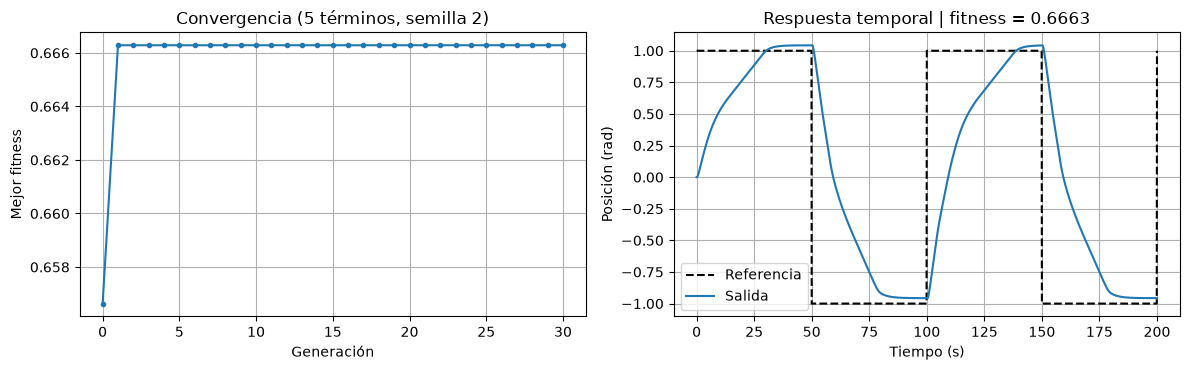

Mejor cromosoma (110 genes) [5 términos | semilla 2]:
[-0.8925 -0.7949 -0.0479  1.0819  1.5708  0.7623  0.8319  1.106   0.6928  0.9065  0.9003  0.3853  0.0678  0.077   0.0913  1.0846  1.
  1.      1.      1.1372 -0.5236 -0.5043 -0.038   0.3997  0.3727  0.2175  0.2823  0.1922  0.2727  0.2469  0.      0.      0.      0.0168
  0.0364  1.2233  1.      1.0151  1.      1.     -6.4629 -7.2405  1.0783  3.2145  8.18    4.2562  2.8886  4.2119  3.8893  4.2494  0.0012
  0.      0.0205  0.0874  0.0138  1.0233  1.      1.      1.      1.108   1.      1.      1.      1.      1.      1.      1.      1.
  1.      1.      1.      1.      1.      0.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.
  3.      0.      0.      0.      0.      1.      1.      1.      1.      3.      0.      1.      2.      3.      4.      3.      3.
  3.      4.      3.      4.      3.      4.      2.      0.    ]


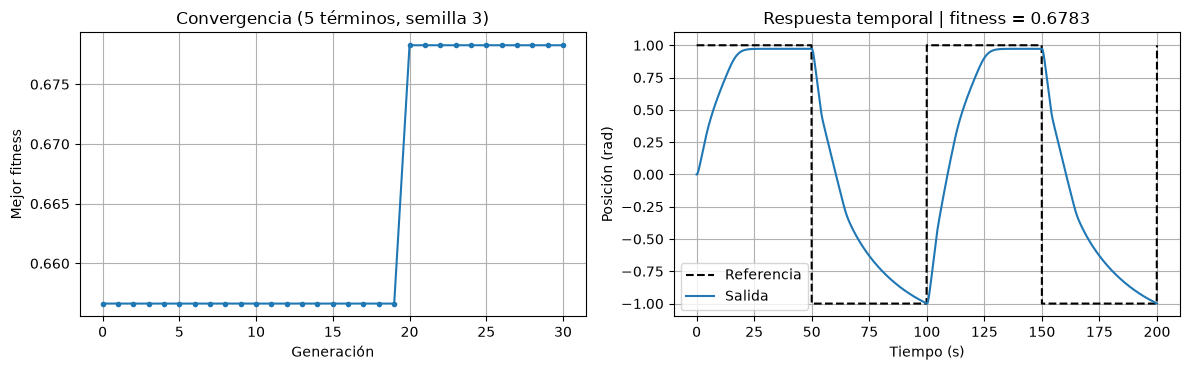

Mejor cromosoma (110 genes) [5 términos | semilla 3]:
[-1.5708 -0.7854  0.      0.7854  1.5708  0.7854  0.7854  0.7854  0.7854  0.7854  0.      0.4598  0.      0.639   0.      2.221   1.
  1.      1.      1.     -0.5236 -0.2618  0.      0.2618  0.5236  0.2618  0.2618  0.2618  0.2618  0.2618  0.      0.      0.      0.
  0.      1.      1.436   1.      1.      1.     -8.18   -0.1687  0.      3.8972  8.18    4.09    4.09    4.09    4.09    3.5647  0.
  0.      0.      0.      0.      1.      1.      1.      1.      1.      1.      0.      1.      0.      0.      1.      1.      0.
  1.      1.      1.      1.      1.      1.      1.      0.      1.      1.      0.      1.      1.      1.      1.      1.      1.
  0.      3.      0.      0.      0.      1.      1.      1.      1.      1.      3.      1.      2.      3.      4.      3.      3.
  3.      3.      3.      0.      4.      4.      4.      3.    ]


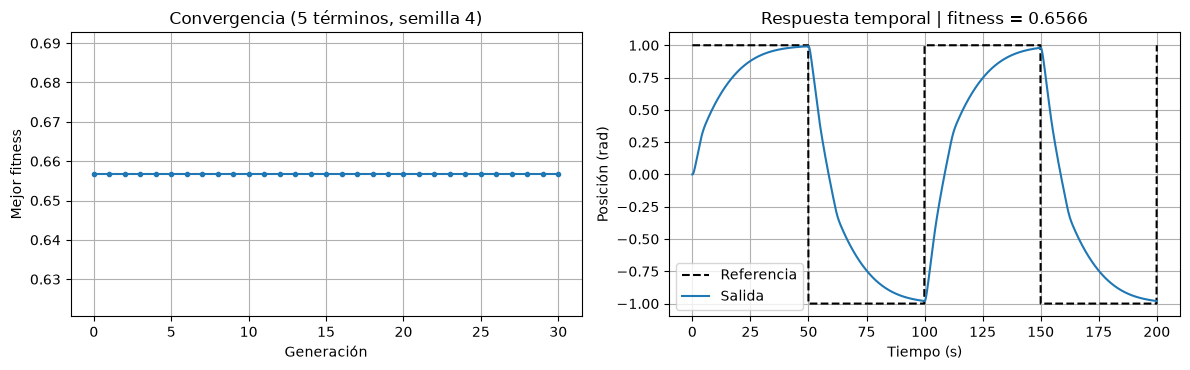

Mejor cromosoma (110 genes) [5 términos | semilla 4]:
[-1.5708 -0.7854  0.      0.7854  1.5708  0.7854  0.7854  0.7854  0.7854  0.7854  0.      0.      0.      0.      0.      1.      1.
  1.      1.      1.     -0.5236 -0.2618  0.      0.2618  0.5236  0.2618  0.2618  0.2618  0.2618  0.2618  0.      0.      0.      0.
  0.      1.      1.      1.      1.      1.     -8.18   -4.09    0.      4.09    8.18    4.09    4.09    4.09    4.09    4.09    0.
  0.      0.      0.      0.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.
  1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.
  0.      0.      0.      0.      0.      1.      1.      1.      1.      1.      0.      1.      2.      3.      4.      3.      3.
  3.      3.      3.      4.      4.      4.      4.      4.    ]


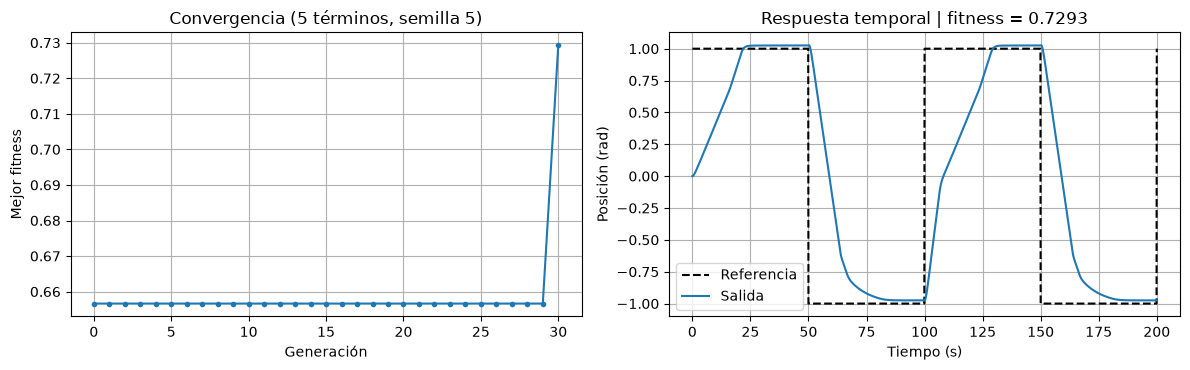

Mejor cromosoma (110 genes) [5 términos | semilla 5]:
[-0.1831  0.0666 -0.6015  0.4369  1.5708  0.2528  0.2598  0.3907  0.7466  0.7854  0.5553  0.7305  0.      0.3799  0.      1.      1.3374
  1.      1.      1.     -0.2182  0.3694  0.     -0.4656  0.5236  0.3845  0.272   0.2618  0.2354  0.2618  0.      0.5814  0.5882  0.
  0.2051  1.4808  1.292   1.7714  1.1959  1.     -8.18   -4.09    0.      4.09    8.18    5.6192  4.09    4.09    4.09    4.09    0.0454
  0.2891  0.3775  0.      0.      1.234   1.4757  1.      2.392   1.      1.      0.      1.      0.      1.      1.      1.      1.
  1.      1.      0.      1.      0.      1.      1.      0.      1.      0.      1.      1.      0.      1.      1.      0.      1.
  4.      4.      0.      0.      4.      2.      1.      1.      4.      1.      0.      4.      2.      1.      4.      2.      3.
  3.      3.      3.      4.      4.      4.      4.      4.    ]


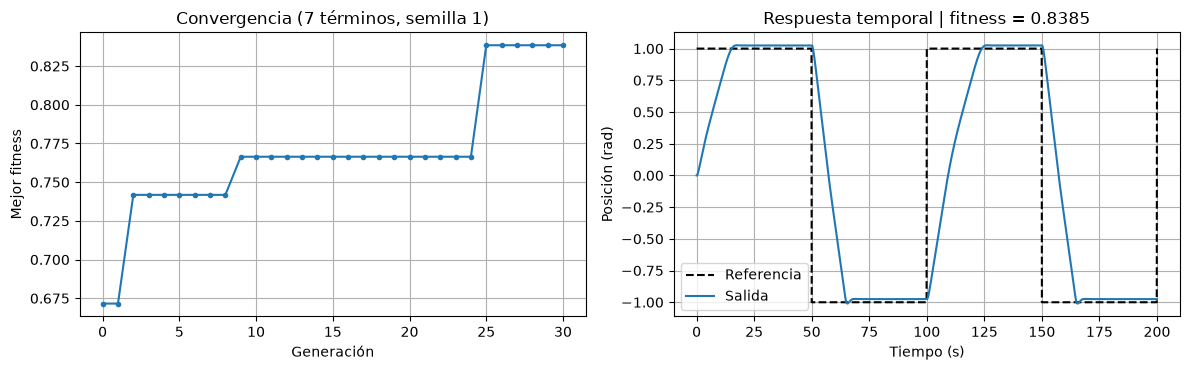

Mejor cromosoma (182 genes) [7 términos | semilla 1]:
[ 0.5089 -1.0472 -0.5236 -0.1662  0.5236  1.0472 -0.7793  0.5845  0.1815  0.4867  0.7478  0.7341  0.5236  0.523   0.6723  0.      0.
  0.      0.      0.0305  0.468   1.      1.6432  1.2038  1.8554  1.      1.659   1.876  -0.5236 -0.3491 -0.1745 -0.4124 -0.1436  0.4116
  0.5236  0.1745  0.2593  0.1745  0.1745  0.2311  0.2429  0.0897  0.      0.      0.      0.8185  0.4306  0.      0.      1.7063  1.
  1.      1.      2.3895  1.0093  1.608  -8.18   -7.1139 -1.2467  5.3399 -7.2966  5.4533  6.2384  2.7267  2.7267  2.7267  2.5985  2.5245
  2.7267  2.6064  0.      0.2644  0.      0.2008  0.      0.5439  0.      1.      1.5049  1.      1.      1.      1.      2.3986  1.
  0.      1.      0.      1.      1.      0.      1.      1.      1.      0.      1.      0.      0.      1.      0.      0.      0.
  1.      1.      1.      0.      1.      0.      1.      0.      0.      1.      1.      1.      1.      1.      1.      0.      1.
  1.   

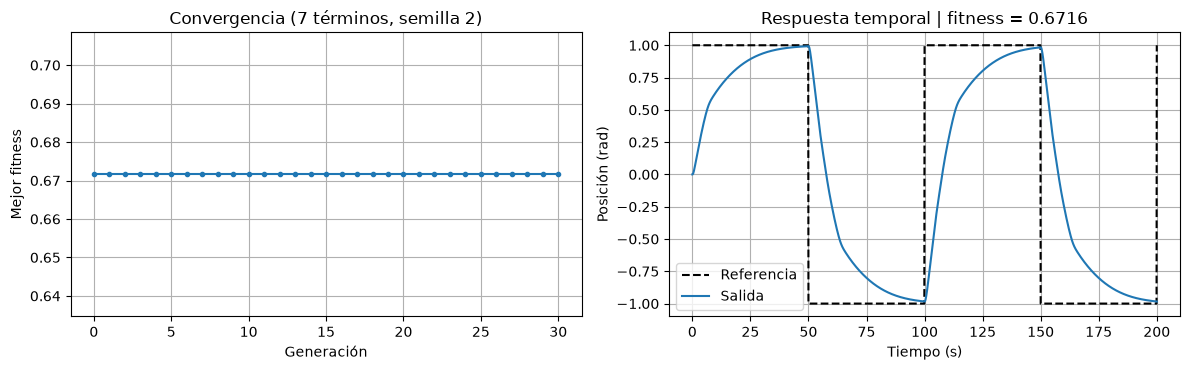

Mejor cromosoma (182 genes) [7 términos | semilla 2]:
[-1.5708 -1.0472 -0.5236  0.      0.5236  1.0472  1.5708  0.5236  0.5236  0.5236  0.5236  0.5236  0.5236  0.5236  0.      0.      0.
  0.      0.      0.      0.      1.      1.      1.      1.      1.      1.      1.     -0.5236 -0.3491 -0.1745  0.      0.1745  0.3491
  0.5236  0.1745  0.1745  0.1745  0.1745  0.1745  0.1745  0.1745  0.      0.      0.      0.      0.      0.      0.      1.      1.
  1.      1.      1.      1.      1.     -8.18   -5.4533 -2.7267  0.      2.7267  5.4533  8.18    2.7267  2.7267  2.7267  2.7267  2.7267
  2.7267  2.7267  0.      0.      0.      0.      0.      0.      0.      1.      1.      1.      1.      1.      1.      1.      1.
  1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.
  1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.
  1.   

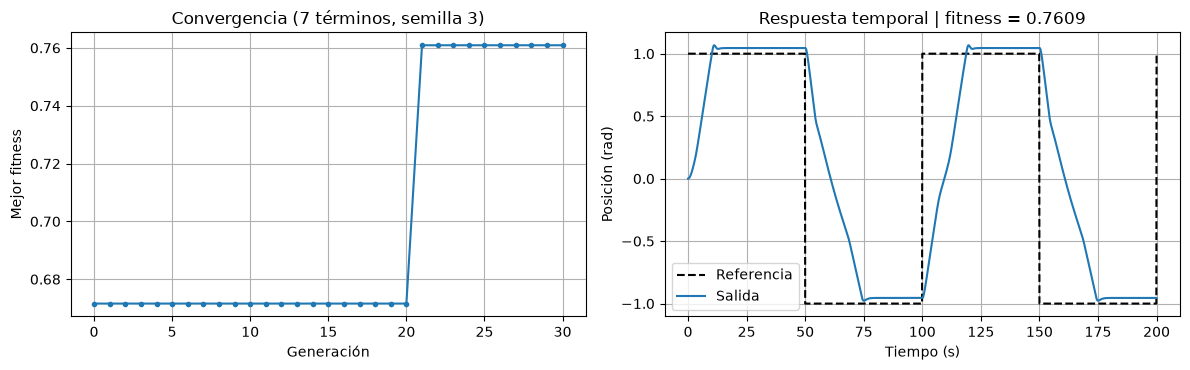

Mejor cromosoma (182 genes) [7 términos | semilla 3]:
[-1.5708 -1.0472 -0.5236 -1.2308  0.5236  1.0472  1.5708  0.5236  0.5236  0.5236  0.5236  0.4096  0.2304  0.5236  0.2618  0.      0.
  0.      0.      0.      0.      1.2639  1.      1.      1.1094  1.4782  1.      1.      0.2139 -0.3491 -0.1745  0.0825 -0.0477  0.3491
  0.5236  0.1745  0.1745  0.1745  0.1254  0.1745  0.1745  0.1745  0.0606  0.      0.      0.1818  0.3398  0.      0.0998  1.      2.1388
  1.      1.      1.6475  1.      1.     -8.18   -5.4533 -2.7267 -3.9494  2.7267 -7.4963  8.18    2.7267  3.0836  2.7267  1.3792  3.2523
  2.7267  2.7267  0.      0.      0.      0.      0.      0.5745  0.7771  1.      1.      1.      2.0509  1.2068  1.7483  2.3346  1.
  1.      1.      1.      1.      1.      1.      0.      0.      0.      1.      0.      1.      0.      0.      1.      1.      1.
  1.      0.      1.      1.      1.      0.      1.      0.      0.      0.      0.      0.      1.      1.      1.      1.      1.
  1

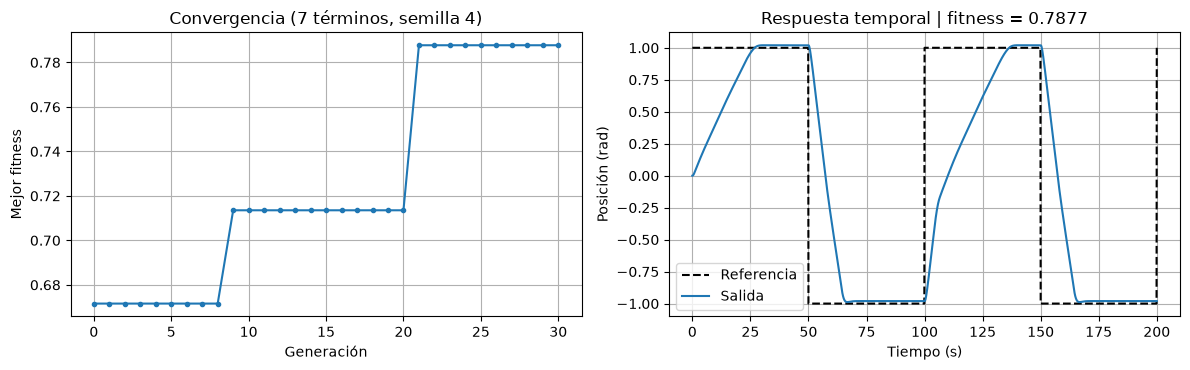

Mejor cromosoma (182 genes) [7 términos | semilla 4]:
[ 0.6373 -1.0472 -0.5236  0.7425  0.5236 -0.7235  1.5708  0.5236  0.7575  0.5388  0.5236  0.5236  0.3287  0.5236  0.      0.1048  0.
  0.0661  0.3822  0.4498  0.      1.513   1.6809  1.      1.      1.      1.      1.     -0.5236 -0.3491 -0.1745  0.      0.4172  0.2182
  0.5236  0.1745  0.1528  0.0604  0.1745  0.1745  0.1745  0.1745  0.      0.8058  0.9144  0.      0.8641  0.1711  0.283   1.      2.0583
  1.      2.4586  1.      1.7076  1.543  -8.18    3.3127 -7.1364  0.      2.7267 -5.0058  8.18    2.7267  2.7267  2.7267  2.7267  2.7267
  1.8739  2.7267  0.3055  0.0529  0.      0.5094  0.4395  0.9108  0.      1.      1.      1.      1.      1.7956  1.      1.      1.
  1.      1.      1.      0.      1.      1.      1.      1.      1.      1.      0.      1.      0.      1.      1.      0.      1.
  1.      1.      1.      1.      0.      0.      1.      1.      1.      1.      1.      0.      0.      1.      0.      1.      0.
  1

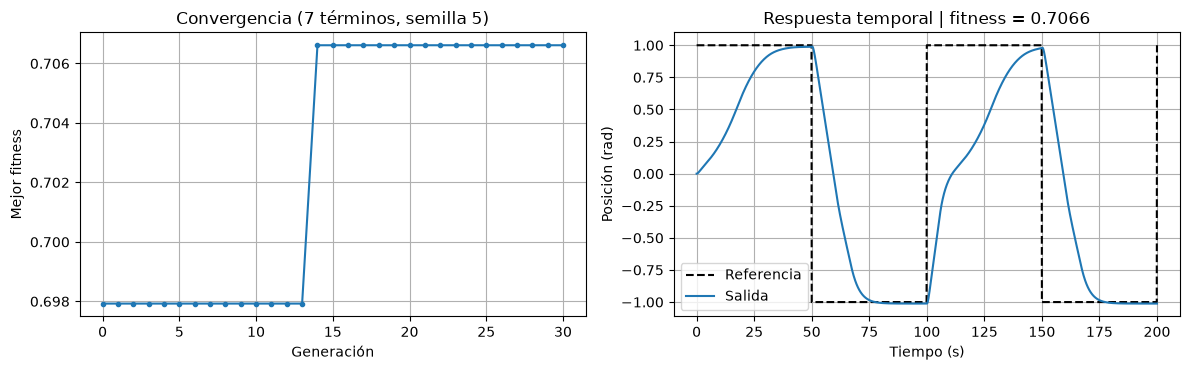

Mejor cromosoma (182 genes) [7 términos | semilla 5]:
[-0.4011 -0.5814 -0.4217  0.5086  1.3338  1.1236  1.4936  0.4956  0.4761  0.5955  0.6581  0.3067  0.4147  0.395   0.0068  0.      0.951
  0.0095  0.      0.0644  0.      1.      2.0103  1.2     1.2757  1.0856  1.0253  1.     -0.5236 -0.2511 -0.2376  0.3384 -0.0368  0.3784
 -0.2425  0.1836  0.2326  0.1982  0.1722  0.2169  0.1785  0.1535  0.4675  0.      0.7797  0.933   0.0025  0.367   0.      1.      1.7018
  1.      1.      2.4863  1.9167  1.008  -7.6084  6.2032 -2.759  -5.5444  5.2043  7.3871  8.18    2.9984  2.4203  3.18    2.7267  2.5994
  2.7351  2.7098  0.9044  0.9465  0.      0.1913  0.3065  0.      0.641   1.4317  1.2825  1.2953  1.1982  1.1172  1.0608  1.      1.
  1.      1.      1.      1.      0.      1.      0.      1.      0.      1.      0.      1.      1.      0.      1.      0.      1.
  1.      1.      0.      0.      1.      1.      0.      1.      1.      1.      1.      1.      0.      1.      1.      1.      1.


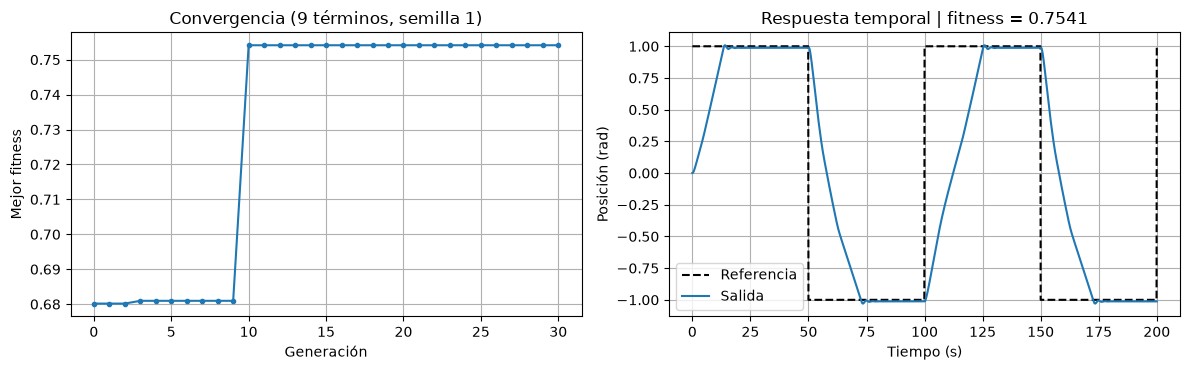

Mejor cromosoma (270 genes) [9 términos | semilla 1]:
[-1.5708 -1.1781 -0.9133 -0.3927  0.2967  0.3927  0.7854  1.1781  1.5708  0.3927  0.3927  0.3927  0.3588  0.2588  0.3927  0.3927  0.3927
  0.3927  0.      0.      0.0894  0.      0.      0.      0.3426  0.      0.      1.      1.5581  1.      1.2823  1.      1.      1.7471
  1.      1.9959 -0.0753 -0.3927 -0.2293 -0.1309  0.      0.2311  0.2618  0.3927  0.5162  0.1248  0.0644  0.1136  0.1086  0.0522  0.1309
  0.1309  0.1126  0.1309  0.6441  0.      0.9183  0.0128  0.      0.      0.0705  0.      0.      1.      1.      1.      1.      1.838
  1.5871  1.3268  1.7939  1.0017 -8.18   -6.135  -2.6378 -2.045   3.1269  2.045   4.09    8.18    3.207   1.5039  2.6965  1.8858  2.1659
  2.045   2.045   2.516   2.8857  2.045   0.169   0.      0.1238  0.      0.      0.      0.      0.      0.4286  1.      1.      1.
  1.      1.1171  1.9119  1.4221  2.2637  1.0552  1.      0.      1.      1.      1.      1.      1.      1.      1.      0.     

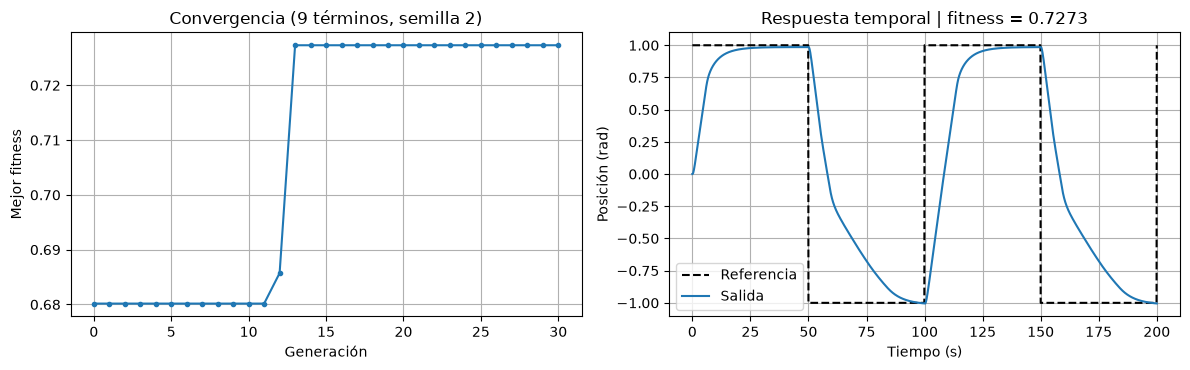

Mejor cromosoma (270 genes) [9 términos | semilla 2]:
[-1.5708 -1.1781 -0.2644 -0.3927  0.4876  0.073   0.7854  0.9488 -1.1895  0.3927  0.3279  0.3927  0.4988  0.2042  0.3927  0.3927  0.4933
  0.1502  0.      0.      0.      0.121   0.2086  0.      0.3539  0.      0.      2.2081  1.      1.7251  1.5675  1.3152  1.      1.
  2.1837  1.     -0.5236 -0.2496 -0.2618 -0.279   0.     -0.2841  0.2618 -0.2521  0.5236  0.1596  0.1309  0.1309  0.1309  0.176   0.0864
  0.1309  0.1309  0.1309  0.7913  0.      0.4448  0.      0.8516  0.      0.2296  0.      0.1942  1.      1.7747  1.      1.1219  1.
  1.      1.      1.      2.2525 -8.18   -6.135  -4.09   -2.045   1.985   2.045  -3.7289  6.135   6.6945  2.045   2.045   2.045   1.3805
  2.045   2.045   2.7057  2.0034  2.045   0.      0.      0.4908  0.      0.      0.8302  0.3966  0.5673  0.      2.0957  1.      1.
  1.      1.3249  1.      1.      1.      2.0169  1.      1.      1.      1.      0.      1.      1.      1.      0.      1.      0.
  0

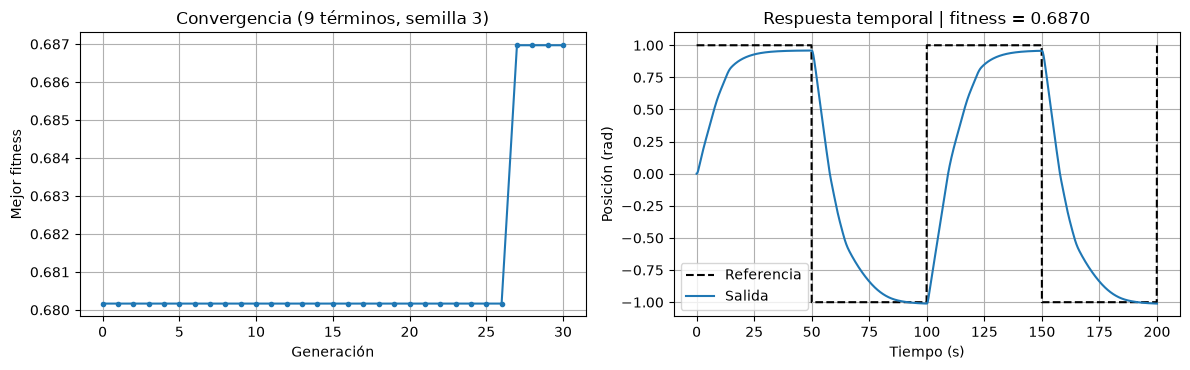

Mejor cromosoma (270 genes) [9 términos | semilla 3]:
[-1.5708 -1.4464 -0.7854 -0.3927 -0.1446  0.3927  0.7854  1.1781  1.5708  0.3927  0.3927  0.3927  0.3927  0.3927  0.3525  0.3927  0.3927
  0.3927  0.      0.7045  0.      0.      0.      0.      0.      0.      0.      1.      1.      2.0366  1.      1.      1.      1.
  1.      1.     -0.5236 -0.2844 -0.2618 -0.1309  0.      0.1309  0.2618  0.3927  0.5236  0.1309  0.1784  0.1309  0.1309  0.1309  0.1309
  0.1309  0.1309  0.0545  0.      0.      0.4576  0.      0.      0.      0.      0.      0.      1.      1.      1.      1.      1.
  1.      1.      1.      1.     -8.18   -6.135  -4.09   -2.045   0.      2.045   4.09    6.135   8.18    2.045   1.8112  2.045   2.045
  2.045   2.045   2.3254  2.045   2.045   0.      0.      0.      0.      0.      0.5111  0.      0.      0.      1.      1.4209  1.
  1.      1.0153  1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      1.      0.      1.      1.
  1.

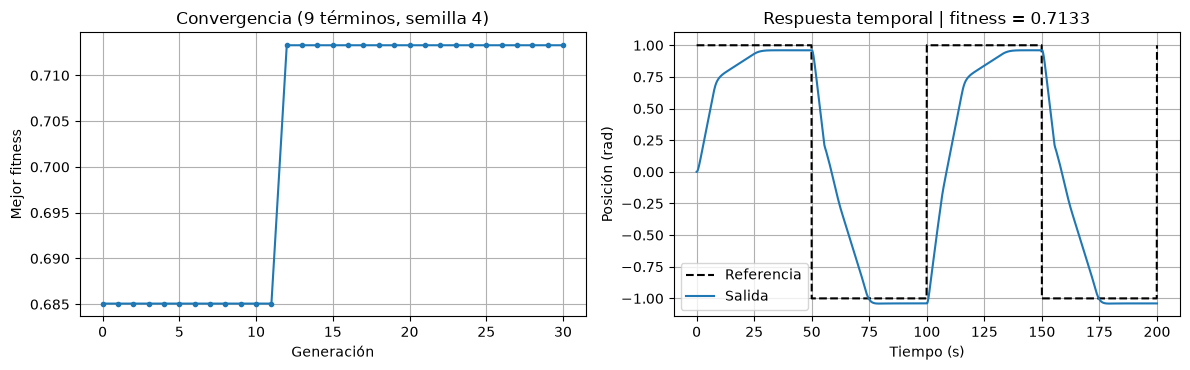

Mejor cromosoma (270 genes) [9 términos | semilla 4]:
[-0.5929 -1.5708 -0.9455 -0.2814  0.0448  0.2467  0.7417  1.5708  1.3803  0.4286  0.325   0.3278  0.4282  0.3615  0.3524  0.5107  0.373
  0.1703  0.5345  0.1416  0.0497  0.6009  0.      0.      0.0049  0.1381  0.1847  1.2495  1.102   1.0163  1.1641  1.      1.      1.0772
  1.      1.     -0.5236 -0.336  -0.2519  0.2896 -0.1771  0.068   0.192   0.3318  0.5236  0.1411  0.142   0.1195  0.0393  0.1533  0.1688
  0.1412  0.1331  0.1361  0.1464  0.1429  0.1009  0.0474  0.      0.      0.0127  0.1075  0.0923  1.      1.0553  1.      1.0068  2.116
  1.      1.0423  1.      2.4151 -7.56   -5.8508 -4.1431 -0.3086  4.0036  1.8843  7.2009  4.3151  7.0824  1.7094  2.1607  2.714   1.7532
  2.2641  2.1038  1.1556  2.2209  2.0566  0.      0.9037  0.      0.103   0.      0.2138  0.0181  0.4962  0.9438  1.      1.      1.
  1.      1.1207  1.0923  1.      1.1803  1.2423  1.      1.      1.      1.      1.      1.      1.      1.      1.      0.      

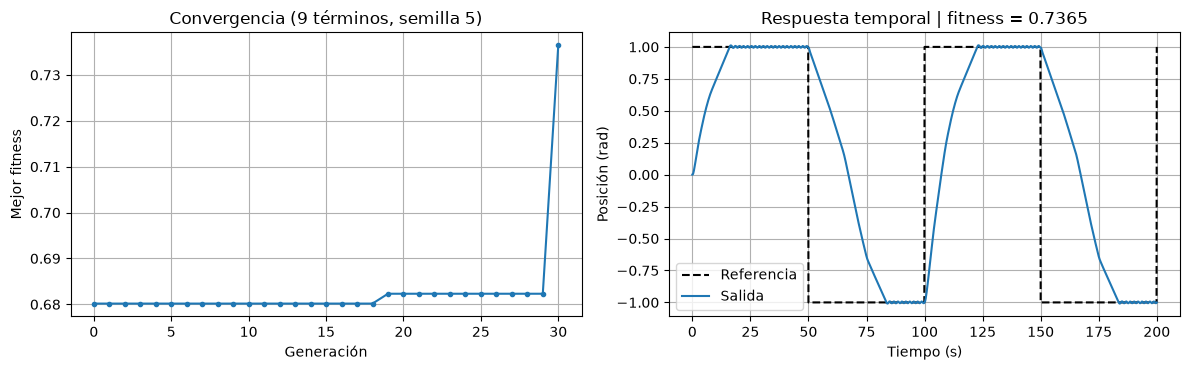

Mejor cromosoma (270 genes) [9 términos | semilla 5]:
[-1.5708 -1.1781 -0.7854 -0.3927  0.      0.3927  0.7854  1.1781  1.5708  0.3927  0.3927  0.3927  0.3927  0.3927  0.3927  0.3927  0.3927
  0.1196  0.      0.      0.      0.2956  0.      0.      0.0603  0.      0.      1.062   1.      1.2875  1.      1.      1.      1.
  1.      1.     -0.5236 -0.3927 -0.2618 -0.1309  0.      0.1309  0.3982  0.3927  0.5236  0.1309  0.1309  0.1309  0.0777  0.1309  0.0906
  0.1309  0.1309  0.1309  0.      0.1694  0.      0.      0.      0.      0.      0.205   0.      1.      1.      1.      1.      1.6136
  1.      1.      1.      1.     -8.18   -6.135  -4.09   -2.045   0.      2.045   4.09    6.135   8.18    0.9221  2.9414  2.045   0.7168
  2.045   2.045   0.5864  2.045   1.2722  0.      0.      0.      0.      0.      0.9863  0.      0.      0.      1.      1.2683  1.0899
  1.      1.      1.      1.      1.      1.      1.      1.      0.      1.      1.      1.      1.      1.      1.      1.    

In [59]:
np.set_printoptions(linewidth=140, precision=4, suppress=True)
for (n, semilla), res in resultados_ag.items():
    fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
    ejes[0].plot(res['historial'], marker='o', ms=3)
    ejes[0].set_xlabel('Generación')
    ejes[0].set_ylabel('Mejor fitness')
    ejes[0].set_title(f'Convergencia ({n} términos, semilla {semilla})')
    ejes[0].grid(True)
    ejes[1].plot(t, r, 'k--', label='Referencia')
    ejes[1].plot(t, res['evaluacion']['theta'], label='Salida')
    ejes[1].set_xlabel('Tiempo (s)')
    ejes[1].set_ylabel('Posición (rad)')
    ejes[1].set_title(f"Respuesta temporal | fitness = {res['fitness']:.4f}")
    ejes[1].grid(True)
    ejes[1].legend()
    plt.tight_layout()
    plt.show()
    print(f"Mejor cromosoma ({res['n_genes']} genes) [{n} términos | semilla {semilla}]:")
    print(res['genes'])

## Funciones de membresía y reglas activas

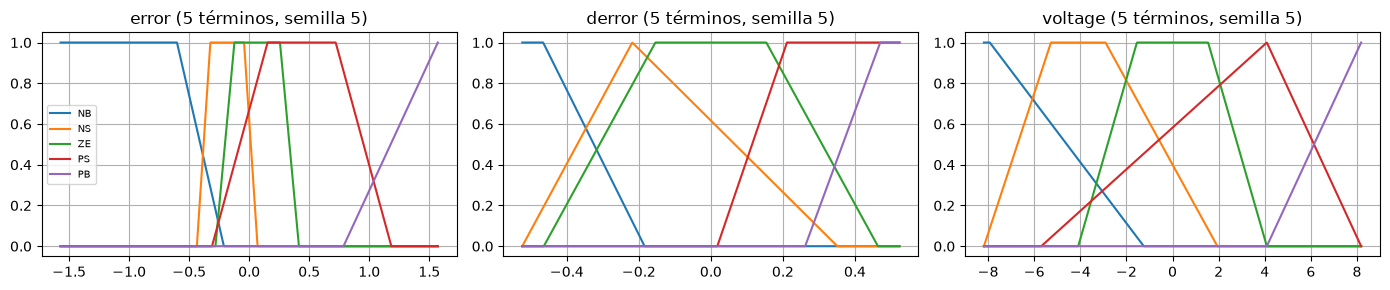

5 términos | semilla 5 | fitness 0.7293 | 17 de 25 reglas activas:
   1. SI error es NB Y derror es NB ENTONCES voltage es PB
   2. SI error es NB Y derror es ZE ENTONCES voltage es NB
   3. SI error es NB Y derror es PB ENTONCES voltage es PB
   4. SI error es NS Y derror es NB ENTONCES voltage es ZE
   5. SI error es NS Y derror es NS ENTONCES voltage es NS
   6. SI error es NS Y derror es ZE ENTONCES voltage es NS
   7. SI error es NS Y derror es PS ENTONCES voltage es PB
   8. SI error es NS Y derror es PB ENTONCES voltage es NS
   9. SI error es ZE Y derror es NS ENTONCES voltage es PB
  10. SI error es ZE Y derror es PS ENTONCES voltage es NS
  11. SI error es ZE Y derror es PB ENTONCES voltage es PB
  12. SI error es PS Y derror es NS ENTONCES voltage es PS
  13. SI error es PS Y derror es PS ENTONCES voltage es PS
  14. SI error es PS Y derror es PB ENTONCES voltage es PS
  15. SI error es PB Y derror es NS ENTONCES voltage es PB
  16. SI error es PB Y derror es ZE ENTONCES vol

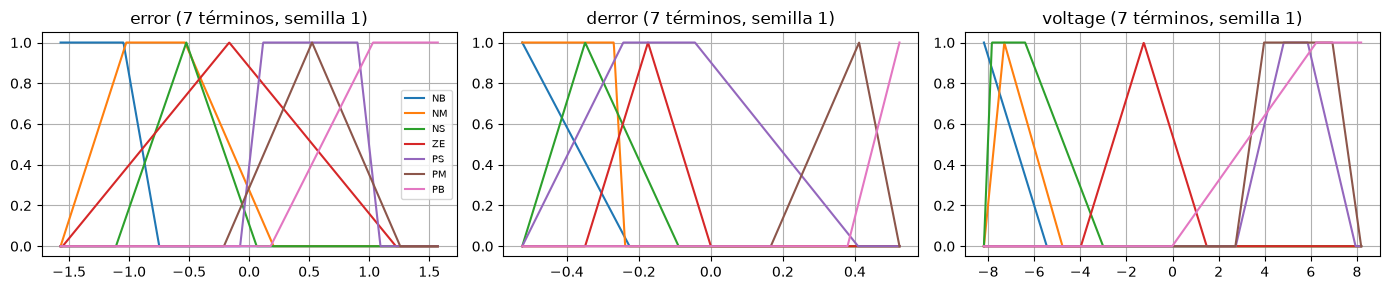

7 términos | semilla 1 | fitness 0.8385 | 31 de 49 reglas activas:
   1. SI error es NB Y derror es NB ENTONCES voltage es NB
   2. SI error es NB Y derror es NS ENTONCES voltage es NB
   3. SI error es NB Y derror es PS ENTONCES voltage es NB
   4. SI error es NB Y derror es PM ENTONCES voltage es NB
   5. SI error es NM Y derror es NB ENTONCES voltage es NM
   6. SI error es NM Y derror es NM ENTONCES voltage es NS
   7. SI error es NM Y derror es NS ENTONCES voltage es NB
   8. SI error es NM Y derror es PS ENTONCES voltage es NB
   9. SI error es NS Y derror es NB ENTONCES voltage es NS
  10. SI error es NS Y derror es PS ENTONCES voltage es NS
  11. SI error es NS Y derror es PM ENTONCES voltage es NS
  12. SI error es NS Y derror es PB ENTONCES voltage es ZE
  13. SI error es ZE Y derror es NM ENTONCES voltage es NM
  14. SI error es ZE Y derror es ZE ENTONCES voltage es ZE
  15. SI error es ZE Y derror es PB ENTONCES voltage es NB
  16. SI error es PS Y derror es NB ENTONCES vol

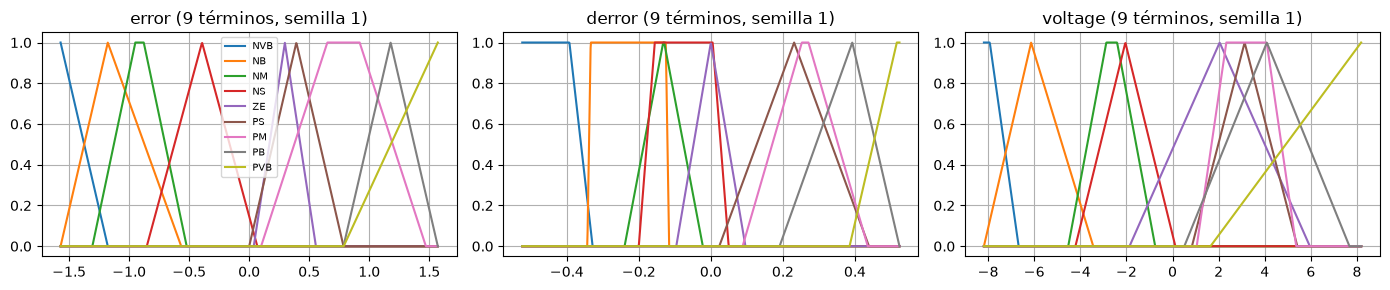

9 términos | semilla 1 | fitness 0.7541 | 61 de 81 reglas activas:
   1. SI error es NVB Y derror es NVB ENTONCES voltage es PM
   2. SI error es NVB Y derror es NM ENTONCES voltage es NVB
   3. SI error es NVB Y derror es NS ENTONCES voltage es NVB
   4. SI error es NVB Y derror es ZE ENTONCES voltage es NVB
   5. SI error es NVB Y derror es PS ENTONCES voltage es NVB
   6. SI error es NVB Y derror es PM ENTONCES voltage es NVB
   7. SI error es NVB Y derror es PB ENTONCES voltage es NB
   8. SI error es NVB Y derror es PVB ENTONCES voltage es NVB
   9. SI error es NB Y derror es NB ENTONCES voltage es NS
  10. SI error es NB Y derror es NS ENTONCES voltage es NB
  11. SI error es NB Y derror es ZE ENTONCES voltage es NB
  12. SI error es NB Y derror es PS ENTONCES voltage es NB
  13. SI error es NB Y derror es PM ENTONCES voltage es NB
  14. SI error es NB Y derror es PVB ENTONCES voltage es NB
  15. SI error es NM Y derror es NVB ENTONCES voltage es NM
  16. SI error es NM Y derror 

In [60]:
for n in TERMINOS:
    mejor = max((resultados_ag[(n, s)] for s in SEMILLAS), key=lambda x: x['fitness'])
    mfs, _, _, _ = decodificar(mejor['genes'], n)
    fig, ejes = plt.subplots(1, 3, figsize=(14, 3))
    for eje, (nombre, lo, hi), vertices in zip(ejes, UNIVERSOS, mfs):
        x = np.linspace(lo, hi, 1000)
        for nom, vertice in zip(NOMBRES[n], vertices):
            eje.plot(x, fuzz.trapmf(x, vertice), label=nom)
        eje.set_title(f'{nombre} ({n} términos, semilla {mejor["semilla"]})')
        eje.grid(True)
    ejes[0].legend(fontsize=7)
    plt.tight_layout()
    plt.show()
    print(f"{n} términos | semilla {mejor['semilla']} | fitness {mejor['fitness']:.4f} | "
          f"{len(mejor['reglas'])} de {n * n} reglas activas:")
    for k, regla in enumerate(mejor['reglas'], 1):
        print(f'  {k:>2}. {regla}')

### Tabla comparativa de resultados
Las métricas son el promedio ± la desviación estándar muestral (n − 1) de las 5 semillas, medidas en el mejor individuo de cada corrida. "Fitness máximo" es el mejor de las 5 corridas.

In [61]:
def valores(clave, n):
    return np.array([resultados_ag[(n, s)]['evaluacion'].get(clave, np.nan) for s in SEMILLAS], dtype=float)

def promedio_desviacion(v, formato='{:.4g}'):
    finitos = v[np.isfinite(v)]                                # t_r o t_s infinito: la respuesta no se estableció
    texto = (formato + ' ± ' + formato).format(finitos.mean(), finitos.std(ddof=1))
    return texto if len(finitos) == len(v) else texto + f' ({len(v) - len(finitos)} sin valor)'

fitness = {n: np.array([resultados_ag[(n, s)]['fitness'] for s in SEMILLAS]) for n in TERMINOS}
filas_tabla = [('Fitness promedio', ['{:.4f}'.format(fitness[n].mean()) for n in TERMINOS]),
               ('Fitness máximo', ['{:.4f}'.format(fitness[n].max()) for n in TERMINOS]),
               ('Desviación estándar', ['{:.4f}'.format(fitness[n].std(ddof=1)) for n in TERMINOS])]
for clave in ('OS+', 'OS-', 'SSE+', 'SSE-', 'tr+', 'tr-', 'ts+', 'ts-'):
    filas_tabla.append((clave, [promedio_desviacion(valores(clave, n)) for n in TERMINOS]))
filas_tabla.append(('Reglas activas (cantidad)', [promedio_desviacion(valores('reglas_activas', n), '{:.3g}') for n in TERMINOS]))
filas_tabla.append(('Parámetros optimizados', [str(num_genes(n)) for n in TERMINOS]))
filas_tabla.append(('Tiempo de optimización (s)', [promedio_desviacion(np.array([resultados_ag[(n, s)]['tiempo_optimizacion'] for s in SEMILLAS]), '{:.1f}') for n in TERMINOS]))
filas_tabla.append(('Inferencia promedio (ms)', [promedio_desviacion(valores('inferencia_ms', n), '{:.3f}') for n in TERMINOS]))
filas_tabla.append(('RAM durante la optimización (MB)', [promedio_desviacion(np.array([resultados_ag[(n, s)]['ram_mb'] for s in SEMILLAS]), '{:.0f}') for n in TERMINOS]))
filas_tabla.append(('Memoria del controlador (MB)', [promedio_desviacion(np.array([resultados_ag[(n, s)]['mem_controlador_mb'] for s in SEMILLAS]), '{:.3f}') for n in TERMINOS]))

print(f"{'Métrica':<34}" + ''.join(f'{str(n) + " términos":>26}' for n in TERMINOS))
for nombre, celdas in filas_tabla:
    print(f'{nombre:<34}' + ''.join(f'{celda:>26}' for celda in celdas))
print('\nFitness de los controladores base (Fase 1): ' + ', '.join(f"{nombre} = {resultados[nombre]['fitness']:.4f}" for nombre in resultados))

Métrica                                           5 términos                7 términos                9 términos
Fitness promedio                                      0.6774                    0.7531                    0.7236
Fitness máximo                                        0.7293                    0.8385                    0.7541
Desviación estándar                                   0.0303                    0.0659                    0.0253
OS+                                            1.337 ± 1.923             2.273 ± 2.762            0.4206 ± 0.602
OS-                                                    0 ± 0           0.4455 ± 0.6117             1.897 ± 1.561
SSE+                                       0.01036 ± 0.02913       -0.003087 ± 0.03417         0.02421 ± 0.01907
SSE-                                     -0.03273 ± 0.007435         -0.0223 ± 0.01777         0.00479 ± 0.01988
tr+                                            24.78 ± 2.942             23.62 ± 7.463          

### **Fase 3:** Selección del mejor individuo

- el mejor individuo del sistema de 5 términos;
- el mejor individuo del sistema de 7 términos;
- el mejor individuo del sistema de 9 términos.

In [62]:
def mejor_de(n):
    return max((resultados_ag[(n, s)] for s in SEMILLAS), key=lambda x: x['fitness'])

mejores = {n: mejor_de(n) for n in TERMINOS}
filas_mejor = [('Semilla', lambda m, n: str(m['semilla'])), ('Fitness total', lambda m, n: f"{m['fitness']:.4f}")]
for clave in ('OS+', 'OS-', 'SSE+', 'SSE-', 'tr+', 'tr-', 'ts+', 'ts-', 'q'):
    filas_mejor.append((clave, lambda m, n, c=clave: f"{m['evaluacion'][c]:.4f}"))
filas_mejor += [('Reglas activas', lambda m, n: f"{len(m['reglas'])} de {n * n}"),
                ('Parámetros optimizados', lambda m, n: str(m['n_genes'])),
                ('Tiempo de inferencia (ms)', lambda m, n: f"{m['evaluacion']['inferencia_ms']:.3f}"),
                ('Tiempo de optimización (s)', lambda m, n: f"{m['tiempo_optimizacion']:.0f}"),
                ('RAM durante la optimización (MB)', lambda m, n: f"{m['ram_mb']:.0f}"),
                ('Memoria del controlador (MB)', lambda m, n: f"{m['mem_controlador_mb']:.3f}")]
print(f"{'Mejor individuo de cada tamaño':<34}" + ''.join(f'{str(n) + " términos":>16}' for n in TERMINOS))
for nombre, formato in filas_mejor:
    print(f'{nombre:<34}' + ''.join(f'{formato(mejores[n], n):>16}' for n in TERMINOS))
print('\nLas reglas activas de cada uno se listan arriba, en "Funciones de membresía y reglas activas".')

Mejor individuo de cada tamaño          5 términos      7 términos      9 términos
Semilla                                          5               1               1
Fitness total                               0.7293          0.8385          0.7541
OS+                                         2.5095          2.6286          0.8042
OS-                                         0.0000          1.0495          2.9597
SSE+                                       -0.0213         -0.0220          0.0121
SSE-                                       -0.0285         -0.0234          0.0116
tr+                                        23.9000         17.9000         20.2000
tr-                                        14.8000         11.3000         17.2000
ts+                                        28.3000         22.6000         24.8000
ts-                                        28.9000         14.5000         21.8000
q                                           0.9865          0.9871          0.9961
Regl

### **Fase 4:** Evaluación del costo computacional

- **Tiempo total de optimización:** Tiempo requerido para completar todas las generaciones del algoritmo genético.
- **Tiempo promedio de inferencia:** Tiempo promedio requerido para generar una salida del controlador difuso.
- **Número de parámetros optimizados:** Cantidad total de genes presentes en el cromosoma.
- **El número y exactamente qué reglas quedaron activas:** Cantidad de reglas ﬁnalmente utilizadas por la mejor solución encontrada y además cuáles fueron seleccionadas.
- **Uso de memoria:** Uso aproximado de memoria asociado al controlador obtenido.

### **Fase 5:** Repetibilidad Experimental

Los algoritmos genéticos son métodos estocásticos. Por esta razón, todos los experimentos deben repetirse como mínimo 5 veces utilizando semillas aleatorias distintas.

In [63]:
def evaluar_con_dt(genes, n, dt_nuevo):
    """Evalúa un individuo con otro paso de simulación y restaura el original al terminar."""
    global dt, t, r
    dt_ant, t_ant, r_ant = dt, t, r
    dt = dt_nuevo
    t = np.arange(0, T_SIM + dt, dt)
    r = square(2*np.pi*t/PERIODO)
    try:
        return evaluar_individuo(genes, n)
    finally:
        dt, t, r = dt_ant, t_ant, r_ant

robustez_dt = {}
print(f"{'':<8}{'dt':>6}{'fitness':>9}{'OS+':>8}{'OS-':>8}{'SSE+':>9}{'SSE-':>9}{'tr+':>7}{'tr-':>7}{'ts+':>7}{'ts-':>7}")
for n in TERMINOS:
    robustez_dt[n] = evaluar_con_dt(mejores[n]['genes'], n, 0.01)
    for etiqueta, ev, paso in ((f'{n} términos', mejores[n]['evaluacion'], dt), ('', robustez_dt[n], 0.01)):
        print(f"{etiqueta:<8}{paso:>6}{ev['fitness']:>9.4f}{ev['OS+']:>8.3f}{ev['OS-']:>8.3f}{ev['SSE+']:>9.4f}{ev['SSE-']:>9.4f}"
              f"{ev['tr+']:>7.1f}{ev['tr-']:>7.1f}{ev['ts+']:>7.1f}{ev['ts-']:>7.1f}")

            dt  fitness     OS+     OS-     SSE+     SSE-    tr+    tr-    ts+    ts-
5 términos   0.1   0.7293   2.510   0.000  -0.0213  -0.0285   23.9   14.8   28.3   28.9
          0.01   0.7289   2.509   0.000  -0.0209  -0.0284   24.0   14.8   28.3   28.9
7 términos   0.1   0.8385   2.629   1.050  -0.0220  -0.0234   17.9   11.3   22.6   14.5
          0.01   0.8389   2.608   0.577  -0.0220  -0.0235   17.9   11.3   22.6   14.5
9 términos   0.1   0.7541   0.804   2.960   0.0121   0.0116   20.2   17.2   24.8   21.8
          0.01   0.7548   0.517   2.748   0.0122   0.0115   20.2   17.2   24.8   21.7
